Number of arms: 10

Epsilon-Greedy Results
-----------------------------
Q-values: [-0.02 -0.12 -1.04 -0.25 -0.03 -0.49 -0.53 -0.08  0.01 -0.3 ]
Arm selection counts: [ 38  11  10  21  66   7   8  60 261  18]
Average reward: -0.07064834015608308


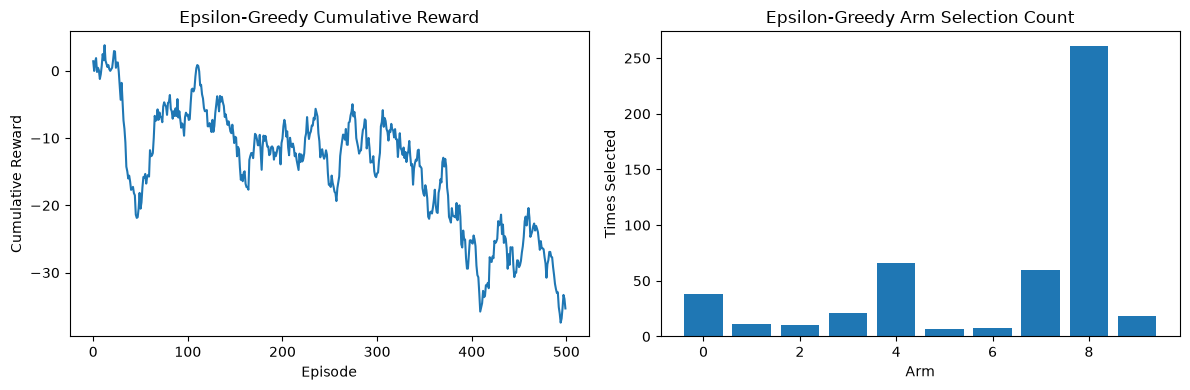


Softmax Results
-----------------------------
Q-values: [ 0.04 -0.44  0.09  0.05 -0.5  -1.97 -0.26  0.24  0.08  0.18]
Arm selection counts: [46 29 65 73 34  1 56 66 49 81]
Average reward: -0.00043493599586520303


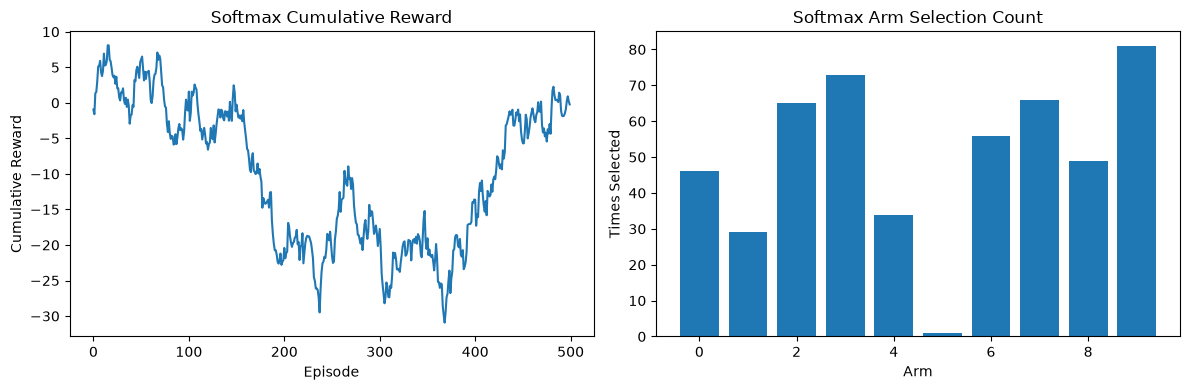

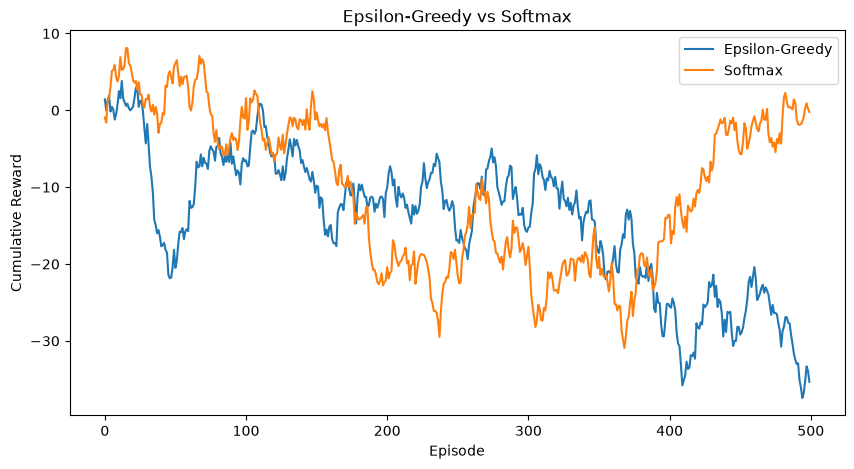

In [2]:
# ============================================================
# INSTALL REQUIRED LIBRARIES
# ============================================================

# Install the Gym library for reinforcement learning environments
!pip install gym gym_bandits

# ============================================================
# IMPORT LIBRARIES
# ============================================================

# Import the Gym package
import gym

# Import the Multi-Armed Bandit environments
import gym_bandits

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Fix compatibility issue between NumPy and Gym
np.bool8 = np.bool_

# ============================================================
# CREATE MULTI-ARMED BANDIT ENVIRONMENT
# ============================================================

# Create the Multi-Armed Bandit environment
base_env = gym.make("MultiarmedBandits-v0")

# Access the original environment without wrappers
env = base_env.unwrapped

# Get the total number of bandit arms
n_arms = env.action_space.n

# Set the total number of episodes
episodes = 500

# Display the number of available arms
print("Number of arms:", n_arms)

# ============================================================
# EPSILON-GREEDY POLICY
# ============================================================

# Set exploration probability
epsilon = 0.1

# Initialize estimated Q-values for all arms
q_values = np.zeros(n_arms)

# Initialize the selection count for each arm
counts = np.zeros(n_arms)

# Store rewards obtained in each episode
rewards = []

# Repeat the experiment for all episodes
for episode in range(episodes):

    # Reset the environment before each episode
    env.reset()

    # Generate a random number to decide exploration or exploitation
    if np.random.rand() < epsilon:

        # Select a random arm (Exploration)
        action = env.action_space.sample()

    else:

        # Select the arm with the highest estimated reward (Exploitation)
        action = np.argmax(q_values)

    # Execute the selected action and receive the reward
    observation, reward, done, info = env.step(action)

    # gym_bandits returns a 1-element array; convert to a scalar
    reward = float(np.squeeze(reward))

    # Increase the count for the selected arm
    counts[action] += 1

    # Update the estimated Q-value using incremental averaging
    q_values[action] += (reward - q_values[action]) / counts[action]

    # Store the received reward
    rewards.append(reward)

# Display the results
print("\nEpsilon-Greedy Results")
print("-----------------------------")

# Print estimated Q-values
print("Q-values:", np.round(q_values, 2))

# Print how many times each arm was selected
print("Arm selection counts:", counts.astype(int))

# Print the average reward obtained
print("Average reward:", np.mean(rewards))

# ============================================================
# PLOT EPSILON-GREEDY RESULTS
# ============================================================

# Create a figure with two plots
plt.figure(figsize=(12, 4))

# Create the first subplot
plt.subplot(1, 2, 1)

# Plot cumulative rewards
plt.plot(np.cumsum(rewards))

# Set graph title
plt.title("Epsilon-Greedy Cumulative Reward")

# Label the x-axis
plt.xlabel("Episode")

# Label the y-axis
plt.ylabel("Cumulative Reward")

# Create the second subplot
plt.subplot(1, 2, 2)

# Plot arm selection counts
plt.bar(range(n_arms), counts)

# Set graph title
plt.title("Epsilon-Greedy Arm Selection Count")

# Label the x-axis
plt.xlabel("Arm")

# Label the y-axis
plt.ylabel("Times Selected")

# Adjust spacing between plots
plt.tight_layout()

# Display the plots
plt.show()

# ============================================================
# SOFTMAX POLICY
# ============================================================

# Set the Softmax temperature parameter
temperature = 0.5

# Initialize Q-values for Softmax
q_values_softmax = np.zeros(n_arms)

# Initialize selection counts for Softmax
counts_softmax = np.zeros(n_arms)

# Store rewards obtained by Softmax
rewards_softmax = []

# Run the Softmax algorithm for all episodes
for episode in range(episodes):

    # Reset the environment
    env.reset()

    # Compute exponentials of Q-values
    probabilities = np.exp(q_values_softmax / temperature)

    # Normalize to obtain probabilities
    probabilities = probabilities / np.sum(probabilities)

    # Select an action according to the probability distribution
    action = np.random.choice(n_arms, p=probabilities)

    # Execute the selected action
    observation, reward, done, info = env.step(action)

    # gym_bandits returns a 1-element array; convert to a scalar
    reward = float(np.squeeze(reward))

    # Update the selection count
    counts_softmax[action] += 1

    # Update the estimated Q-value
    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]

    # Store the reward
    rewards_softmax.append(reward)

# Display Softmax results
print("\nSoftmax Results")
print("-----------------------------")

# Print estimated Q-values
print("Q-values:", np.round(q_values_softmax, 2))

# Print arm selection counts
print("Arm selection counts:", counts_softmax.astype(int))

# Print average reward
print("Average reward:", np.mean(rewards_softmax))

# ============================================================
# PLOT SOFTMAX RESULTS
# ============================================================

# Create a figure with two plots
plt.figure(figsize=(12, 4))

# Create the first subplot
plt.subplot(1, 2, 1)

# Plot cumulative rewards
plt.plot(np.cumsum(rewards_softmax))

# Set graph title
plt.title("Softmax Cumulative Reward")

# Label the x-axis
plt.xlabel("Episode")

# Label the y-axis
plt.ylabel("Cumulative Reward")

# Create the second subplot
plt.subplot(1, 2, 2)

# Plot arm selection counts
plt.bar(range(n_arms), counts_softmax)

# Set graph title
plt.title("Softmax Arm Selection Count")

# Label the x-axis
plt.xlabel("Arm")

# Label the y-axis
plt.ylabel("Times Selected")

# Adjust spacing
plt.tight_layout()

# Display the plots
plt.show()

# ============================================================
# COMPARE EPSILON-GREEDY AND SOFTMAX
# ============================================================

# Create a comparison figure
plt.figure(figsize=(10, 5))

# Plot cumulative reward for Epsilon-Greedy
plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)

# Plot cumulative reward for Softmax
plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)

# Set graph title
plt.title("Epsilon-Greedy vs Softmax")

# Label the x-axis
plt.xlabel("Episode")

# Label the y-axis
plt.ylabel("Cumulative Reward")

# Display the legend
plt.legend()

# Show the comparison graph
plt.show()

# Close the environment and release resources
env.close()